# Practical 7: Support Vector Machine (SVM)

*Teacher-demo version.* Cells marked **ORIGINAL** are your repository notebook, unchanged. Cells marked **ADDED** are new: input experiments with real outputs, viva questions and common errors. Original file: `Very_Basic_SVM_Experiment.ipynb`

**A. Aim:** To implement Linear, RBF and Polynomial SVM, visualize support vectors and decision boundaries, and try different C and gamma values.

**How to run (every practical)**

1. Install Python 3.10+ and Jupyter, then the libraries: `pip install numpy matplotlib scikit-learn jupyter`
2. Open a terminal / Anaconda Prompt in the folder containing this file and type `jupyter notebook`. Click this notebook.
3. Run cells one by one with **Shift + Enter** (or **Kernel -> Restart & Run All**). Run the cells in order - later cells need variables made by earlier ones.
4. To demonstrate a different result: edit the value on the line marked `# <-- CHANGED` in an experiment cell (or edit the same line in the original cell), then run that cell again. Run **Cell -> Run All** if later cells depend on it.
5. To print: **Ctrl + P** in the browser (as your lab readme suggests).

*Libraries needed here:* numpy, matplotlib, scikit-learn

---
## B / C. ORIGINAL PROGRAM AND ORIGINAL OUTPUT (unchanged cells follow)

<a href="https://colab.research.google.com/github/priyasathe123/ML-Practical-s/blob/main/Very_Basic_SVM_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: Support Vector Machine (SVM)



**Aim:** To implement Linear, RBF and Polynomial SVM, visualize support vectors and decision boundaries, and try different C and gamma values.

**Author: Dr. Priya B. Pandharbale**

**Library:** Scikit-learn and Matplotlib

## 1. Import libraries and create dataset

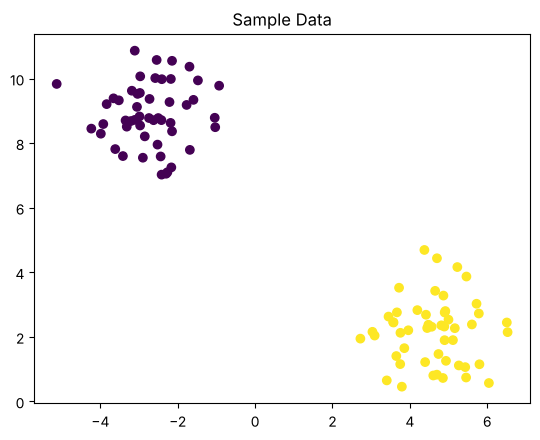

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Create simple dataset
X, y = make_blobs(n_samples=100, centers=2, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Sample Data")
plt.show()

## 2. Train three SVM models

In [2]:
# Linear SVM
linear = SVC(kernel="linear", C=1)
linear.fit(X_train, y_train)

# RBF SVM
rbf = SVC(kernel="rbf", C=1, gamma="scale")
rbf.fit(X_train, y_train)

# Polynomial SVM
poly = SVC(kernel="poly", degree=3, C=1)
poly.fit(X_train, y_train)

print("Linear Accuracy:", accuracy_score(y_test, linear.predict(X_test)))
print("RBF Accuracy:", accuracy_score(y_test, rbf.predict(X_test)))
print("Polynomial Accuracy:", accuracy_score(y_test, poly.predict(X_test)))

Linear Accuracy: 1.0
RBF Accuracy: 1.0
Polynomial Accuracy: 1.0


## 3. Visualize decision boundary and support vectors

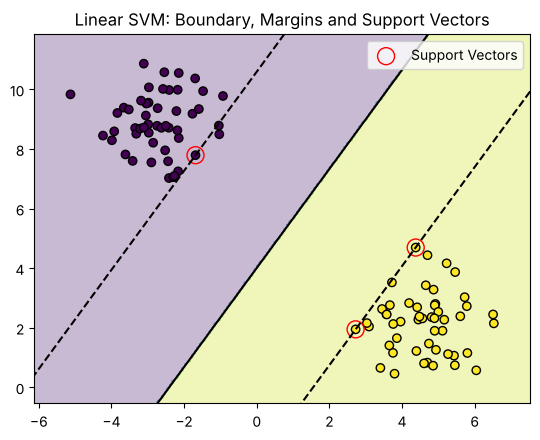

In [3]:
# Select a model to visualize
model = linear

# Make a grid for plotting
import numpy as np
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 200),
    np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 200)
)

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k")
plt.scatter(model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=150, facecolors="none", edgecolors="red",
            label="Support Vectors")

# Show margin lines for linear SVM
if model.kernel == "linear":
    decision = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    decision = decision.reshape(xx.shape)
    plt.contour(xx, yy, decision, levels=[-1, 0, 1],
                colors="black", linestyles=["--", "-", "--"])

plt.title("Linear SVM: Boundary, Margins and Support Vectors")
plt.legend()
plt.show()

**Try another kernel:** In the visualization cell, change `model = linear` to `model = rbf` or `model = poly` and run the cell again. The red circles show support vectors. Margin lines are drawn for the linear SVM.

## 4. Try different C and gamma values

In [4]:
# Try different C values
for c in [0.1, 1, 10]:
    model = SVC(kernel="rbf", C=c, gamma="scale")
    model.fit(X_train, y_train)
    print("C =", c, "Accuracy =", accuracy_score(y_test, model.predict(X_test)))

# Try different gamma values
for g in [0.1, 1, 10]:
    model = SVC(kernel="rbf", C=1, gamma=g)
    model.fit(X_train, y_train)
    print("Gamma =", g, "Accuracy =", accuracy_score(y_test, model.predict(X_test)))

C = 0.1 Accuracy = 1.0
C = 1 Accuracy = 1.0
C = 10 Accuracy = 1.0
Gamma = 0.1 Accuracy = 1.0
Gamma = 1 Accuracy = 1.0
Gamma = 10 Accuracy = 0.9


## Observations
1. SVM separates data into different classes.
2. Linear SVM uses a straight decision boundary.
3. RBF and Polynomial kernels can form curved decision boundaries.
4. Support vectors are the important data points near the boundary.
5. C and gamma values can change the model accuracy.

## Result
Linear, RBF and Polynomial SVM models were trained. Their accuracy was compared, support vectors and decision boundaries were visualized, and different C and gamma values were tested.

---
## D / E / F. INPUT EXPERIMENTS (ADDED)
Each experiment cell is **self-contained** (it re-creates what it needs), so you can run any experiment on its own. Lines ending in `# <-- CHANGED (original: ...)` show exactly what was edited; `# ADDED line` marks new helper lines.

### D. Input Experiment 1 - Overlapping classes

**Changed input:** `make_blobs(... centers=2, random_state=42)` -> add `cluster_std=3.5`

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #1 (section *1. Import libraries and create dataset*).

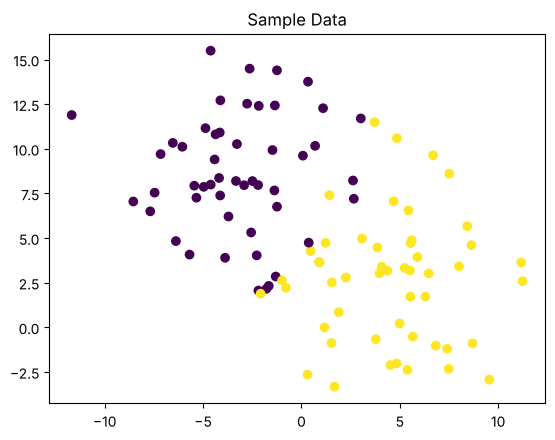

Linear Accuracy: 0.9
RBF Accuracy: 0.85
Polynomial Accuracy: 0.8


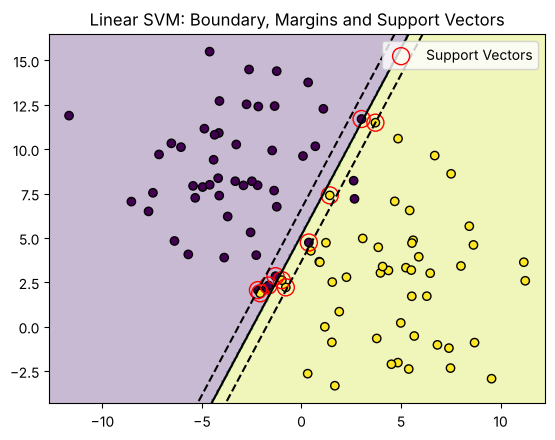

C = 0.1 Accuracy = 0.85
C = 1 Accuracy = 0.85
C = 10 Accuracy = 0.9
Gamma = 0.1 Accuracy = 0.9
Gamma = 1 Accuracy = 0.9
Gamma = 10 Accuracy = 0.65


In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Create simple dataset
X, y = make_blobs(n_samples=100, centers=2, cluster_std=3.5, random_state=42)  # <-- CHANGED (original: X, y = make_blobs(n_samples=100, centers=2, random_state=42))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Sample Data")
plt.show()

# Linear SVM
linear = SVC(kernel="linear", C=1)
linear.fit(X_train, y_train)

# RBF SVM
rbf = SVC(kernel="rbf", C=1, gamma="scale")
rbf.fit(X_train, y_train)

# Polynomial SVM
poly = SVC(kernel="poly", degree=3, C=1)
poly.fit(X_train, y_train)

print("Linear Accuracy:", accuracy_score(y_test, linear.predict(X_test)))
print("RBF Accuracy:", accuracy_score(y_test, rbf.predict(X_test)))
print("Polynomial Accuracy:", accuracy_score(y_test, poly.predict(X_test)))

# Select a model to visualize
model = linear

# Make a grid for plotting
import numpy as np
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 200),
    np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 200)
)

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k")
plt.scatter(model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=150, facecolors="none", edgecolors="red",
            label="Support Vectors")

# Show margin lines for linear SVM
if model.kernel == "linear":
    decision = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    decision = decision.reshape(xx.shape)
    plt.contour(xx, yy, decision, levels=[-1, 0, 1],
                colors="black", linestyles=["--", "-", "--"])

plt.title("Linear SVM: Boundary, Margins and Support Vectors")
plt.legend()
plt.show()

# Try different C values
for c in [0.1, 1, 10]:
    model = SVC(kernel="rbf", C=c, gamma="scale")
    model.fit(X_train, y_train)
    print("C =", c, "Accuracy =", accuracy_score(y_test, model.predict(X_test)))

# Try different gamma values
for g in [0.1, 1, 10]:
    model = SVC(kernel="rbf", C=1, gamma=g)
    model.fit(X_train, y_train)
    print("Gamma =", g, "Accuracy =", accuracy_score(y_test, model.predict(X_test)))

**Actual output explained**

**What changed:** `cluster_std = 3.5` makes the two blobs overlap. Linear **0.90**, RBF **0.85**, Polynomial **0.80** (all 1.0 originally). C = 0.1/1/10 -> 0.85/0.85/0.90; gamma = 0.1/1/10 -> 0.90/0.90/**0.65**.

**Why:** overlapping classes cannot be separated perfectly, so accuracy drops and the kernels start to differ. Gamma = 10 makes the RBF boundary extremely wiggly (it chases individual points) and test accuracy falls to 65 % - overfitting. The straight-line kernel works best here because the true boundary is roughly linear.

### E. Input Experiment 2 - Visualise the RBF kernel

**Changed input:** `model = linear` -> `model = rbf` in Step 3 (plus title)

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #3 (section *3. Visualize decision boundary and support vectors*).

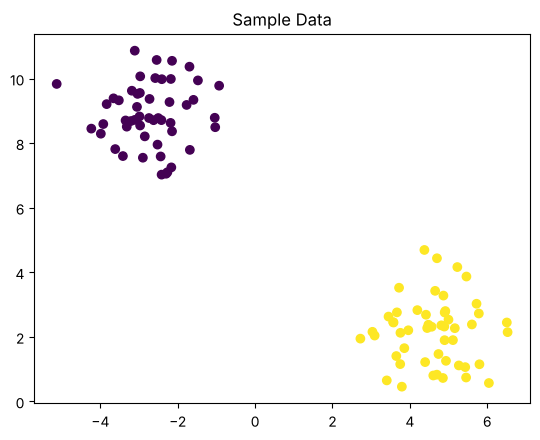

Linear Accuracy: 1.0
RBF Accuracy: 1.0
Polynomial Accuracy: 1.0


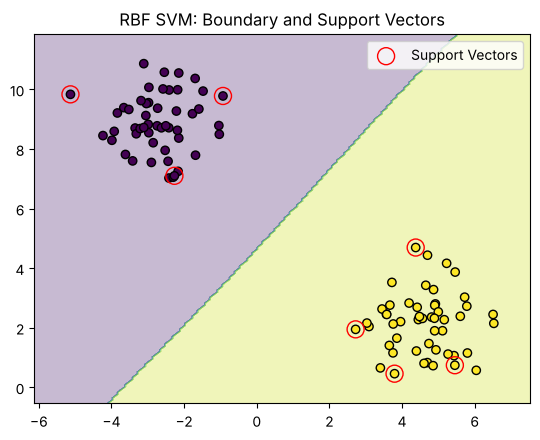

Support vectors per class (RBF): [3 4]


In [6]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Create simple dataset
X, y = make_blobs(n_samples=100, centers=2, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Sample Data")
plt.show()

# Linear SVM
linear = SVC(kernel="linear", C=1)
linear.fit(X_train, y_train)

# RBF SVM
rbf = SVC(kernel="rbf", C=1, gamma="scale")
rbf.fit(X_train, y_train)

# Polynomial SVM
poly = SVC(kernel="poly", degree=3, C=1)
poly.fit(X_train, y_train)

print("Linear Accuracy:", accuracy_score(y_test, linear.predict(X_test)))
print("RBF Accuracy:", accuracy_score(y_test, rbf.predict(X_test)))
print("Polynomial Accuracy:", accuracy_score(y_test, poly.predict(X_test)))

# Select a model to visualize
model = rbf  # <-- CHANGED (original: model = linear)

# Make a grid for plotting
import numpy as np
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 200),
    np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 200)
)

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k")
plt.scatter(model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=150, facecolors="none", edgecolors="red",
            label="Support Vectors")

# Show margin lines for linear SVM
if model.kernel == "linear":
    decision = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    decision = decision.reshape(xx.shape)
    plt.contour(xx, yy, decision, levels=[-1, 0, 1],
                colors="black", linestyles=["--", "-", "--"])

plt.title("RBF SVM: Boundary and Support Vectors")  # <-- CHANGED (original: plt.title("Linear SVM: Boundary, Margins and Support Vectors"))
plt.legend()
plt.show()

print("Support vectors per class (RBF):", rbf.n_support_)   # ADDED line

**Actual output explained**

**What changed:** the visualisation now uses `model = rbf` (and the title was updated, since the original title is hard-coded as 'Linear SVM'). The RBF model has **3 support vectors for class 0 and 4 for class 1** (`[3 4]`). The boundary is curved and no margin lines are drawn (the notebook draws them only for linear kernels).

**Why:** the RBF kernel maps the data to a higher-dimensional space, so the boundary in the original plane can curve. Only the few points nearest the boundary (red circles) become support vectors.

### F. Input Experiment 3 - Extreme C and gamma values

**Changed input:** C list `[0.1,1,10]` -> `[0.001,1,1000]`; gamma list `[0.1,1,10]` -> `[0.001,1,100]`

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #4 (section *4. Try different C and gamma values*).

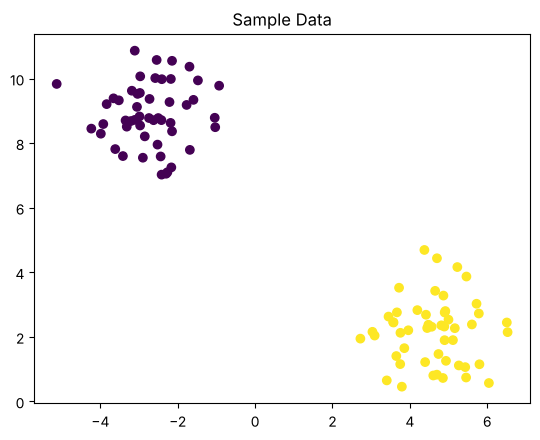

Linear Accuracy: 1.0
RBF Accuracy: 1.0
Polynomial Accuracy: 1.0
C = 0.001 Accuracy = 0.45
C = 1 Accuracy = 1.0
C = 1000 Accuracy = 1.0
Gamma = 0.001 Accuracy = 1.0
Gamma = 1 Accuracy = 1.0
Gamma = 100 Accuracy = 0.75


In [7]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Create simple dataset
X, y = make_blobs(n_samples=100, centers=2, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Sample Data")
plt.show()

# Linear SVM
linear = SVC(kernel="linear", C=1)
linear.fit(X_train, y_train)

# RBF SVM
rbf = SVC(kernel="rbf", C=1, gamma="scale")
rbf.fit(X_train, y_train)

# Polynomial SVM
poly = SVC(kernel="poly", degree=3, C=1)
poly.fit(X_train, y_train)

print("Linear Accuracy:", accuracy_score(y_test, linear.predict(X_test)))
print("RBF Accuracy:", accuracy_score(y_test, rbf.predict(X_test)))
print("Polynomial Accuracy:", accuracy_score(y_test, poly.predict(X_test)))

# Try different C values
for c in [0.001, 1, 1000]:  # <-- CHANGED (original: for c in [0.1, 1, 10]:)
    model = SVC(kernel="rbf", C=c, gamma="scale")
    model.fit(X_train, y_train)
    print("C =", c, "Accuracy =", accuracy_score(y_test, model.predict(X_test)))

# Try different gamma values
for g in [0.001, 1, 100]:  # <-- CHANGED (original: for g in [0.1, 1, 10]:)
    model = SVC(kernel="rbf", C=1, gamma=g)
    model.fit(X_train, y_train)
    print("Gamma =", g, "Accuracy =", accuracy_score(y_test, model.predict(X_test)))

**Actual output explained**

**What changed:** C list `[0.001, 1, 1000]`, gamma list `[0.001, 1, 100]` on the original data. **C = 0.001 gives only 0.45**, C = 1 and 1000 give 1.0; gamma = 0.001 and 1 give 1.0, **gamma = 100 gives 0.75**.

**Why:** with a tiny C the margin penalty dominates and the model is too constrained: it predicts **Class 1 for every test point** (9 of the 20 test points are Class 1, hence 0.45), and almost every training point (78 of 80) becomes a support vector - severe underfitting. A huge gamma makes each support vector's influence extremely local, so the model memorises the training points and fails on test data (overfitting).

---
## G. IMPORTANT VIVA QUESTIONS AND ANSWERS (ADDED)

**Q1. What is a support vector?**  
A training point lying on or inside the margin; only these points determine the decision boundary.

**Q2. What is the margin?**  
The gap between the boundary and the nearest points of each class. SVM chooses the boundary with the largest margin.

**Q3. What is the kernel trick?**  
Computing inner products in a higher-dimensional space without explicitly mapping the data, so linear separation becomes possible for non-linear data (RBF, polynomial).

**Q4. What does C control?**  
The trade-off between a wide margin and training errors. Small C = wide margin, more mistakes allowed (can underfit); large C = fewer training errors (can overfit).

**Q5. What does gamma control in the RBF kernel?**  
How far the influence of one training point reaches. Small gamma = smooth boundary; large gamma = complex, wiggly boundary (overfitting).

**Q6. What does `gamma='scale'` mean?**  
gamma = 1 / (n_features x X.var()), a data-dependent default.

**Q7. Why should data be scaled before SVM?**  
Kernels depend on distances/dot products, so features with large ranges would dominate.

---
## Common errors and solutions (ADDED)

- `AttributeError: 'SVC' object has no attribute 'support_vectors_'` -> the model was not fitted yet.
- Margin lines missing -> they are drawn only when `model.kernel == 'linear'`.
- Slow training with large C or poly kernel -> reduce `degree` or `max_iter`.